<figure><center>
<img src='https://www.economicas.uba.ar/wp-content/uploads/2020/08/cropped-logo_FCE.png''/>
</center></figure>

# Visualización avanzada
### Taller de Programación para el Análisis de Datos — FCE UBA

---

| Sección | Contenido | Librería |
|---|---|---|
| **1. Estadísticos** | regplot, KDE, ECDF, QQ-plot | Matplotlib / Seaborn |
| **2. Geoespaciales** | Mapa base, choropleth, burbujas | GeoPandas |
| **3. Animaciones** | Línea dinámica, bar chart race | FuncAnimation |

```bash
pip install geopandas geodatasets
```

---
## 0. Setup y datasets

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.animation as animation
import seaborn as sns
import geopandas as gpd
import geodatasets
from scipy import stats
from IPython.display import HTML

np.random.seed(42)

In [8]:
# ── Dataset 1: ventas mensuales ──────────────────────────────────
MESES     = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
REGIONES  = ['Norte', 'Centro', 'Sur']
PRODUCTOS = ['Laptop', 'Monitor', 'Teclado', 'Mouse']
PRECIO    = {'Laptop': 1200, 'Monitor': 400, 'Teclado': 80, 'Mouse': 35}

filas = []
for mes_idx, mes in enumerate(MESES):
    for region in REGIONES:
        for producto in PRODUCTOS:
            base       = {'Laptop': 30, 'Monitor': 50, 'Teclado': 120, 'Mouse': 200}[producto]
            tendencia  = 1 + mes_idx * 0.03
            estacional = 1 + 0.25 * np.sin(2 * np.pi * mes_idx / 12 - np.pi / 2)
            rfactor    = {'Norte': 1.2, 'Centro': 1.0, 'Sur': 0.8}[region]
            cantidad   = int(base * tendencia * estacional * rfactor * np.random.uniform(0.85, 1.15))
            filas.append({'Mes': mes, 'MesNum': mes_idx + 1, 'Region': region,
                          'Producto': producto, 'Cantidad': cantidad,
                          'Precio': PRECIO[producto], 'Ingresos': cantidad * PRECIO[producto]})

df_ventas = pd.DataFrame(filas)

In [9]:
# ── Dataset 2: equipo de 300 vendedores ──────────────────────────
N = 300
experiencia  = np.random.exponential(scale=5, size=N).clip(0.5, 20).round(1)
region       = np.random.choice(REGIONES, size=N, p=[0.4, 0.35, 0.25])
producto     = np.random.choice(PRODUCTOS, size=N)

region_calls = {'Norte': 22, 'Centro': 18, 'Sur': 15}
llamadas_dia = np.array([np.random.normal(region_calls[r], 4) for r in region]).clip(5, 40).round(0)
tasa_cierre  = (0.08 + experiencia * 0.012 + np.random.normal(0, 0.04, N)).clip(0.03, 0.40)
cierres_mes  = (llamadas_dia * 22 * tasa_cierre).round(0).astype(int)
precio_prod  = np.array([PRECIO[p] for p in producto])
ticket_base  = precio_prod * np.random.uniform(1.5, 4.0, N)
ingresos_mes = (cierres_mes * ticket_base * (1 + experiencia * 0.03)).round(0)
satisfaccion = (6.5 + experiencia * 0.12 + np.random.normal(0, 1.2, N)).clip(1, 10).round(1)

df_equipo = pd.DataFrame({
    'Experiencia': experiencia, 'Region': region, 'Producto': producto,
    'LlamadasDia': llamadas_dia, 'TasaCierre': tasa_cierre.round(3),
    'CierresMes': cierres_mes, 'IngresosMes': ingresos_mes, 'Satisfaccion': satisfaccion,
})

#df_equipo.describe().round(2)

In [10]:
# ── Dataset 3: ingresos por país ─────────────────────────────────
paises_data = [
    ('Argentina',-38,-63,85000,340), ('Brazil',-10,-55,210000,1100),
    ('Colombia',4,-74,62000,280), ('Chile',-30,-71,74000,310),
    ('Mexico',24,-102,130000,590), ('United States of America',38,-97,520000,2400),
    ('Canada',60,-96,195000,820), ('Germany',51,10,310000,1350),
    ('France',46,2,275000,1180), ('Spain',40,-4,180000,760),
    ('Italy',42,12,165000,690), ('United Kingdom',54,-2,290000,1250),
    ('Japan',36,138,340000,1420), ('China',35,105,480000,2100),
    ('Australia',-25,133,220000,950), ('South Africa',-29,25,95000,390),
    ('India',20,77,145000,680), ('Russia',60,90,110000,430),
]
df_paises = pd.DataFrame(paises_data, columns=['name','lat','lon','ingresos','clientes'])
df_paises['ingresos'] += np.random.randint(-15000, 15000, len(df_paises))
df_paises['clientes'] += np.random.randint(-50, 50, len(df_paises))
#print(f"df_paises: {len(df_paises)} países")

---
# Sección 1

### 1.1 — regplot: regresión lineal con banda de confianza

`sns.regplot` ajusta una recta de regresión sobre los datos y muestra la banda de confianza al 95%.
Cuanto más angosta, más precisa es la estimación.

#### Experiencia vs ingresos (regresión simple)

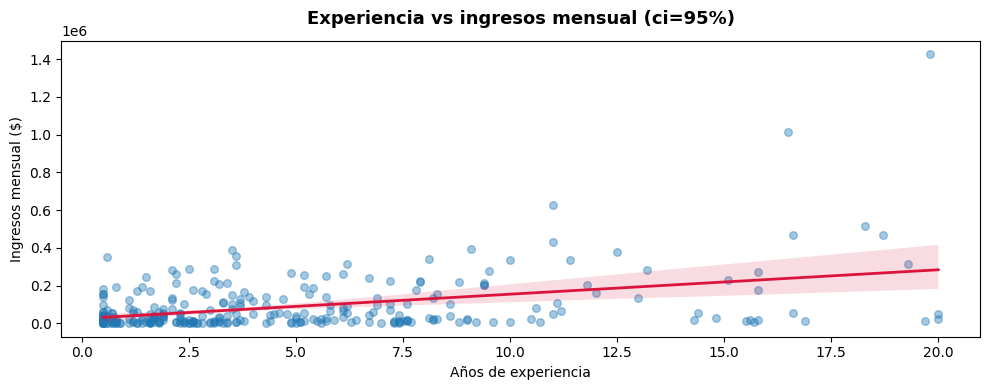

In [8]:
plt.figure(figsize=(10, 4))
sns.regplot(data=df_equipo, x='Experiencia', y='IngresosMes',  scatter_kws={'alpha': 0.4, 's': 30},    line_kws={'color': 'crimson', 'linewidth': 2},   ci=95)

plt.title('Experiencia vs ingresos mensual (ci=95%)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Años de experiencia')
plt.ylabel('Ingresos mensual ($)')
#plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
plt.tight_layout()
plt.show()

#### Regresión por región

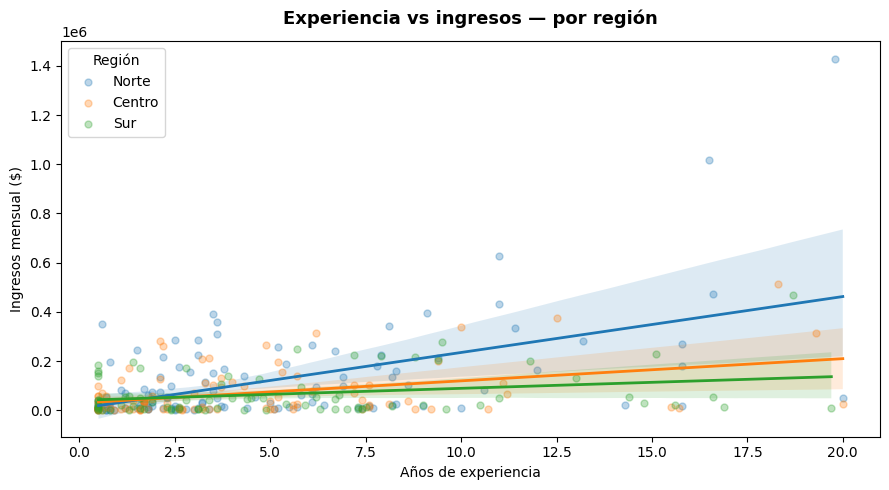

In [9]:
plt.figure(figsize=(9, 5))
for region in REGIONES:
    datos = df_equipo[df_equipo['Region'] == region]
    sns.regplot(data=datos, x='Experiencia', y='IngresosMes',
                scatter_kws={'alpha': 0.3, 's': 25},
                line_kws={'linewidth': 2},
                label=region, ci=95)

plt.title('Experiencia vs ingresos — por región', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Años de experiencia')
plt.ylabel('Ingresos mensual ($)')
#plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
plt.legend(title='Región')
plt.tight_layout()
plt.show()

### 1.2 — Distribuciones: KDE y ECDF

### KDE con área rellena + rug plot

El KDE (Kernel Density Estimate) estima la densidad de probabilidad de forma continua.

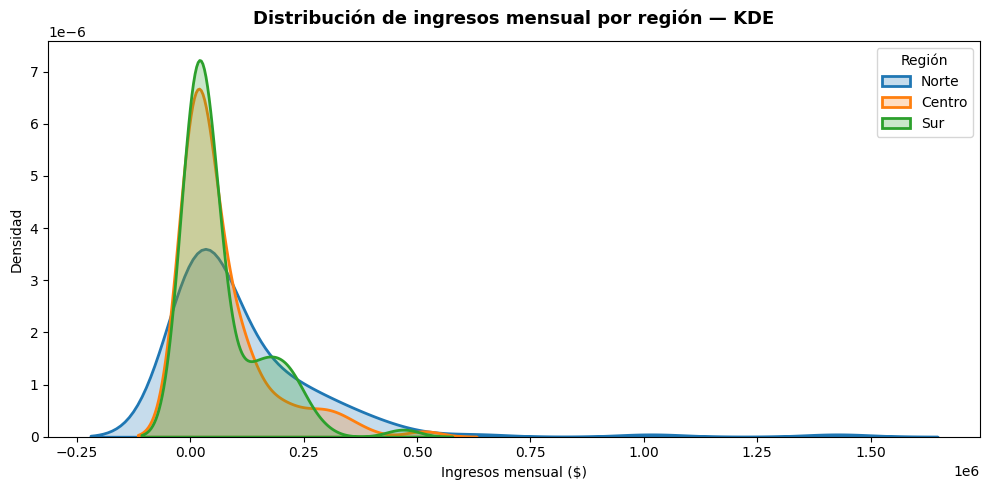

In [13]:
plt.figure(figsize=(10, 5))
for region in REGIONES:
    datos = df_equipo[df_equipo['Region'] == region]['IngresosMes']
    sns.kdeplot(datos, label=region, fill=True, alpha=0.25, linewidth=2)

plt.title('Distribución de ingresos mensual por región — KDE', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Ingresos mensual ($)')
plt.ylabel('Densidad')
#plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
plt.legend(title='Región')
plt.tight_layout()
plt.show()

### ECDF — Distribución acumulada empírica

Para cada valor x, el ECDF muestra qué proporción de vendedores tiene un ingreso ≤ x.
Permite comparar distribuciones sin asumir ninguna forma paramétrica.

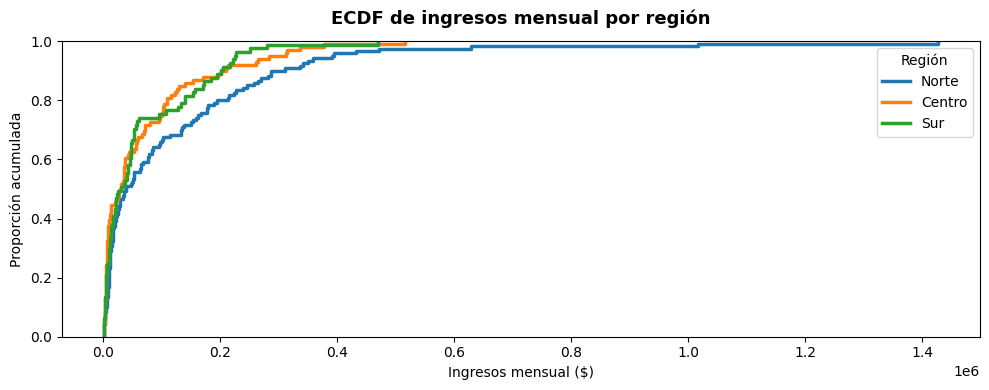

In [15]:
plt.figure(figsize=(10, 4))
for region in REGIONES:
    datos = df_equipo[df_equipo['Region'] == region]['IngresosMes']
    sns.ecdfplot(datos, label=region, linewidth=2.5)

plt.title('ECDF de ingresos mensual por región', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Ingresos mensual ($)')
plt.ylabel('Proporción acumulada')
#plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
plt.legend(title='Región')
plt.tight_layout()
plt.show()

### 1.3 — QQ-plot

Compara la distribución de los datos contra la distribución normal teórica.
- Puntos sobre la diagonal → distribución aproximadamente normal
- Desvíos en los extremos → colas asimétricas o más pesadas

#### Satisfacción del cliente (esperamos normal)

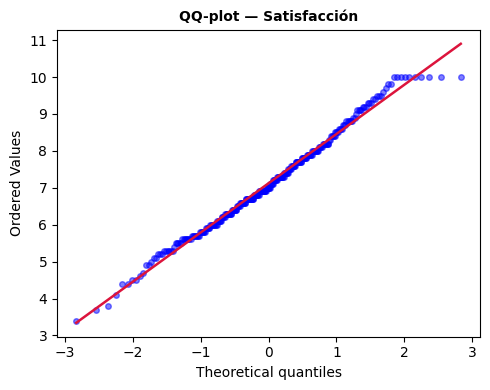

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))

stats.probplot(df_equipo['Satisfaccion'], dist='norm', plot=ax)

ax.set_title('QQ-plot — Satisfacción', fontweight='bold', fontsize=10)
ax.get_lines()[0].set(markersize=4, alpha=0.5)
ax.get_lines()[1].set(color='crimson', linewidth=1.8)
plt.tight_layout()
plt.show()

#### Ingresos mensual (esperamos asimétrico hacia la derecha)

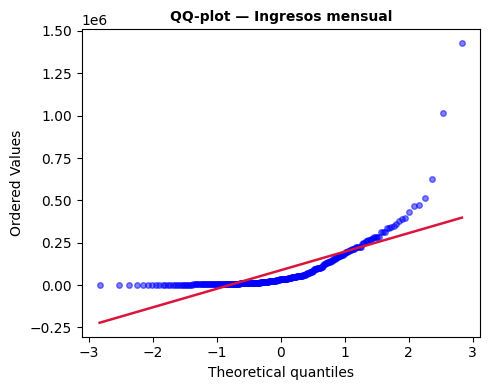

In [17]:
fig, ax = plt.subplots(figsize=(5, 4))
stats.probplot(df_equipo['IngresosMes'], dist='norm', plot=ax)
ax.set_title('QQ-plot — Ingresos mensual', fontweight='bold', fontsize=10)
ax.get_lines()[0].set(markersize=4, alpha=0.5)
ax.get_lines()[1].set(color='crimson', linewidth=1.8)
plt.tight_layout()
plt.show()

#### log(Ingresos) — ¿se normaliza con la transformación logarítmica?

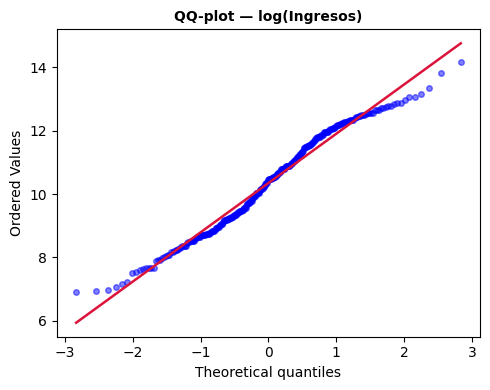

In [18]:
fig, ax = plt.subplots(figsize=(5, 4))
stats.probplot(df_equipo['IngresosMes'].apply(np.log), dist='norm', plot=ax)
ax.set_title('QQ-plot — log(Ingresos)', fontweight='bold', fontsize=10)
ax.get_lines()[0].set(markersize=4, alpha=0.5)
ax.get_lines()[1].set(color='crimson', linewidth=1.8)
plt.tight_layout()
plt.show()

---
# Sección 2 — Gráficos geoespaciales

### 2.1 — Mapa base

In [4]:
try:
    # Intentamos cargar el mapa desde el paquete geodatasets (instalado localmente)
    mundo = gpd.read_file(geodatasets.get_path('naturalearth_lowres'))
except Exception:
    # Si geodatasets no está disponible, descargamos el shapefile directamente desde internet
    URL_MAP = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
    mundo = gpd.read_file(URL_MAP)
    mundo = mundo.rename(columns={'NAME': 'name', 'CONTINENT': 'continent', 'POP_EST': 'pop_est'})

print(f"Columnas: {mundo.columns.tolist()}")

Columnas: ['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'name', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'pop_est', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_VN', 'ADM0_A

<Figure size 2000x800 with 0 Axes>

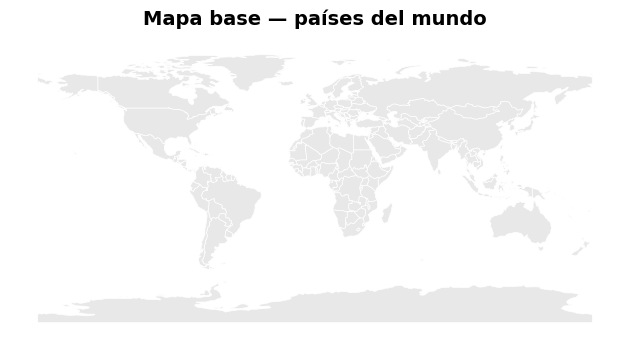

In [5]:
plt.figure(figsize=(20, 8))
mundo.plot(color='#e8e8e8', edgecolor='white', linewidth=0.5)

plt.title('Mapa base — países del mundo', fontsize=14, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.show()

### 2.2 — Ingresos por país

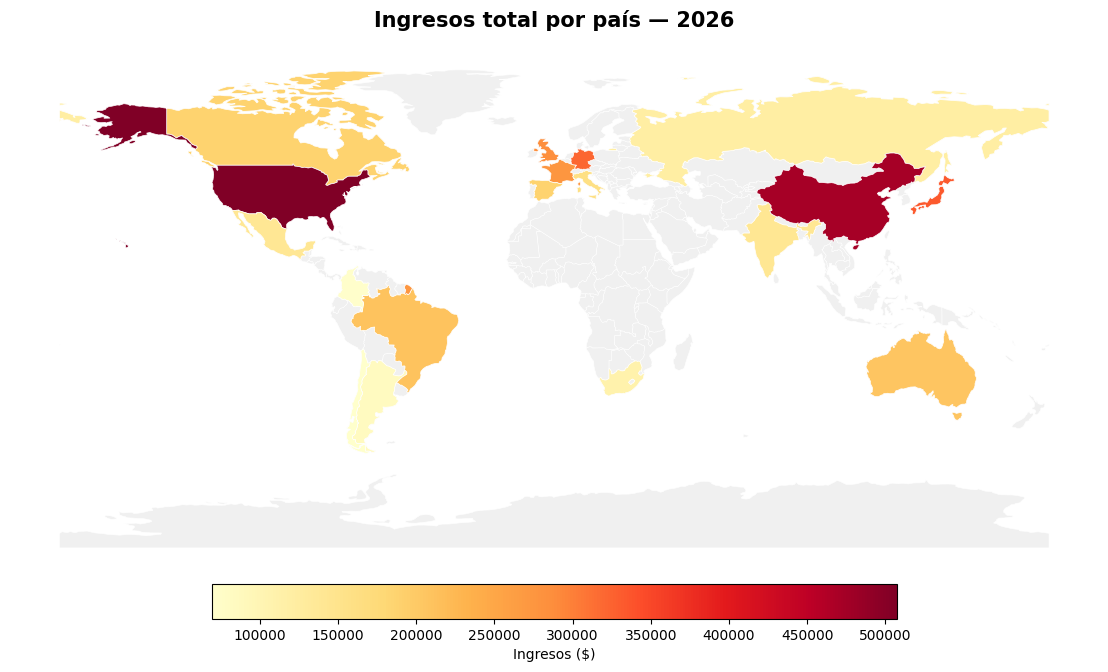

In [11]:
'''Une el GeoDataFrame del mundo con nuestros datos de ingresos/clientes, usando el nombre del país como clave. 
how='left' significa que se conservan todos los países del mapa — los que no están en df_paises quedan con NaN en ingresos.'''
mundo_rev = mundo.merge(df_paises[['name', 'ingresos', 'clientes']], on='name', how='left')

'''Se debe usar subplots para obtener ax. Si no se pasa ax=ax en cada plot(), cada .plot() abre una figura nueva y las capas quedan separadas.'''
fig, ax = plt.subplots(figsize=(14, 7))

'''Dibuja primero los países sin datos en gris claro'''
mundo_rev.plot( ax=ax, color='#f0f0f0', edgecolor='white', linewidth=0.4)

'''Dibuja los países con datos, coloreando cada uno según su valor de ingresos. cmap='YlOrRd' es la paleta amarillo → naranja → rojo: valores bajos quedan claros, valores altos quedan oscuros.'''
mundo_rev.plot( ax=ax, column='ingresos', cmap='YlOrRd', edgecolor='white',  linewidth=0.5,  legend=True, legend_kwds={'label': 'Ingresos ($)', 'orientation': 'horizontal', 'shrink': 0.5, 'pad': 0.02})

ax.set_title('Ingresos total por país — 2026', fontsize=15, fontweight='bold', pad=14)
ax.axis('off')
plt.tight_layout()
plt.show()

### 2.3 — Mapa de burbujas

Tamaño del punto → ingresos · Color del punto → número de clientes

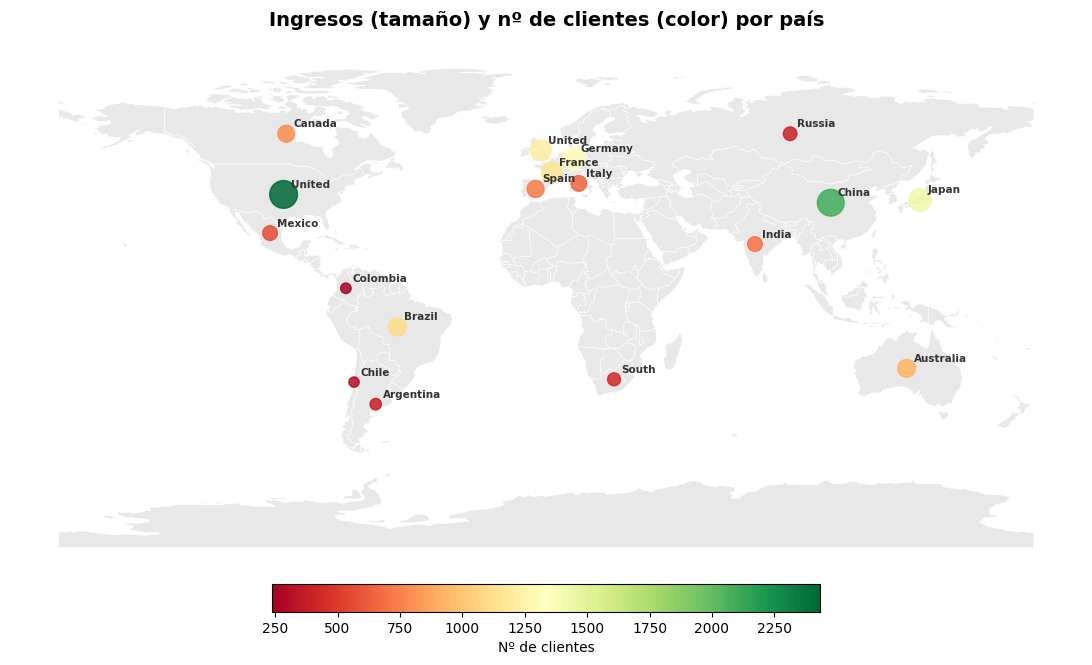

In [ ]:
# Convierte df_paises en un GeoDataFrame agregando una columna de geometría
# gpd.points_from_xy construye un punto geográfico a partir de longitud y latitud
# crs='EPSG:4326' indica que las coordenadas están en sistema WGS84 (latitud/longitud estándar)
gdf_puntos = gpd.GeoDataFrame( df_paises, geometry=gpd.points_from_xy(df_paises['lon'], df_paises['lat']), crs='EPSG:4326' )

# Eje compartido para superponer el mapa base y las burbujas
fig, ax = plt.subplots(figsize=(14, 7))

# Capa 1: mapa base con todos los países en gris (fondo)
mundo.plot(ax=ax, color='#e8e8e8', edgecolor='white', linewidth=0.4)

# Capa 2: burbujas sobre los países con datos
gdf_puntos.plot(
    ax=ax,
    column='clientes',           # el COLOR de cada burbuja representa el nº de clientes
    cmap='RdYlGn',               # rojo = pocos clientes, verde = muchos
    markersize=gdf_puntos['ingresos'] / gdf_puntos['ingresos'].max() * 400,  # el TAMAÑO representa los ingresos
    alpha=0.85,                  # ligera transparencia para ver superposiciones
    legend=True,
    legend_kwds={'label': 'Nº de clientes', 'orientation': 'horizontal', 'shrink': 0.4, 'pad': 0.02}
)

# Etiqueta con el primer nombre del país, desplazada 5px arriba y a la derecha del punto
for _, row in gdf_puntos.iterrows():
    ax.annotate(
        row['name'].split(' ')[0],           # solo la primera palabra (ej: "United" en vez de "United States...")
        xy=(row['lon'], row['lat']),         # posición del punto en el mapa
        xytext=(5, 5), textcoords='offset points',  # desplazamiento del texto respecto al punto
        fontsize=7.5, color='#333333', fontweight='bold'
    )

ax.set_title('Ingresos (tamaño) y nº de clientes (color) por país', fontsize=14, fontweight='bold', pad=14)
ax.axis('off')
plt.tight_layout()
plt.show()

---
## Sección 3 — Animaciones con FuncAnimation

### 3.1 — Línea que crece mes a mes

In [29]:
# Ingresos totales por mes (suma de todas las regiones y productos)
ing_mensual = df_ventas.groupby('MesNum')['Ingresos'].sum().reset_index()

fig, ax = plt.subplots(figsize=(9, 4))

def actualizar_linea(frame):
    ax.clear()

    # Datos hasta el mes actual (el frame avanza de 0 a 11)
    datos = ing_mensual.iloc[:frame + 1]

    # Línea principal con marcadores en cada mes
    ax.plot(datos['MesNum'], datos['Ingresos'],
            color='steelblue', linewidth=2.5, marker='o', markersize=6)

    # Área sombreada bajo la línea
    ax.fill_between(datos['MesNum'], datos['Ingresos'], alpha=0.15, color='steelblue')

    # Punto destacado en el mes actual
    ax.scatter(datos['MesNum'].iloc[-1], datos['Ingresos'].iloc[-1], color='crimson', zorder=5, s=90)

    # Límites fijos para que el eje no salte entre frames
    ax.set_xlim(0.5, 12.5)
    ax.set_ylim(0, ing_mensual['Ingresos'].max() * 1.15)

    # Etiquetas del eje x con nombres de meses en lugar de números
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MESES)

    #ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))

    ax.set_title(f'Ingresos mensual — {MESES[frame]}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Mes')
    ax.set_ylabel('Ingresos ($)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# frames: cantidad de pasos = cantidad de meses
# interval: milisegundos entre cada frame
ani_linea = animation.FuncAnimation(
    fig, actualizar_linea,
    frames=len(ing_mensual),
    interval=400,
    repeat=True
)

# plt.close() evita que matplotlib muestre una figura estática vacía
plt.close()

# Renderiza la animación como HTML interactivo dentro de la notebook
HTML(ani_linea.to_jshtml())

## 3.3 — Exportar como GIF

```bash
pip install pillow
```

In [ ]:
# Descomentá para exportar

# ani_linea.save('ingresos_mensual.gif', writer='pillow', fps=2)
# print('✅ Guardado: ingresos_mensual.gif')

# ani_barras.save('bar_chart_race.gif', writer='pillow', fps=1)
# print('✅ Guardado: bar_chart_race.gif')

In [13]:
X = df_paises[['ingresos', 'clientes']].values.astype(float)
X_norm = (X - X.mean(axis=0)) / X.std(axis=0)

In [ ]:
# ── K-means manual — guardamos cada iteración para la animación ───
K = 3
COLORES = ['#2a78d6', '#eb6834', '#1baf7a']

# Centroides iniciales: 3 puntos elegidos al azar
idx_init = np.random.choice(len(X_norm), K, replace=False)
centroides = X_norm[idx_init].copy()

# Guardamos el estado de cada iteración: (etiquetas, centroides)
historial = []

for _ in range(10):
    # Paso 1 — Asignación: cada punto va al centroide más cercano
    distancias = np.array([np.linalg.norm(X_norm - c, axis=1) for c in centroides])
    etiquetas  = np.argmin(distancias, axis=0)

    historial.append((etiquetas.copy(), centroides.copy()))

    # Paso 2 — Actualización: centroide al promedio de su cluster
    nuevos_centroides = np.array([X_norm[etiquetas == k].mean(axis=0) for k in range(K)])

    # Convergencia: los centroides no se movieron
    if np.allclose(centroides, nuevos_centroides):
        break

    centroides = nuevos_centroides

print(f"Convergió en {len(historial)} iteraciones")

Convergió en 6 iteraciones


In [44]:
# ── Animación ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

def actualizar(frame):
    ax.clear()
    etiquetas, cents = historial[frame]

    # Puntos coloreados según su cluster actual
    for k in range(K):
        mask = etiquetas == k
        ax.scatter(X[mask, 0], X[mask, 1],  color=COLORES[k], s=80, alpha=0.85, zorder=2, label=f'Cluster {k+1}')
        # Nombre del país junto a cada punto
        for i in np.where(mask)[0]:
            ax.annotate(df_paises['name'].iloc[i], xy=(X[i, 0], X[i, 1]), xytext=(5, 4), textcoords='offset points', fontsize=7.5, color='#333333')

    # Centroides marcados con estrella ★
    cents_orig = cents * X.std(axis=0) + X.mean(axis=0)
    ax.scatter(cents_orig[:, 0], cents_orig[:, 1], color=COLORES, s=220, marker='*',  edgecolors='black', linewidths=0.8, zorder=3)

    ax.set_title(f'K-means',   fontsize=13, fontweight='bold')
    ax.set_xlabel('Ingresos ($)')
    ax.set_ylabel('Nº de clientes')
    ax.legend(loc='upper left', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

ani_kmeans = animation.FuncAnimation(
    fig, actualizar,
    frames=len(historial),
    interval=900,
    repeat=True
)

plt.close()
HTML(ani_kmeans.to_jshtml())